### <font color = "gold"> Import les librairies requises

In [2]:
# Importer les packages
import pandas as pd
import numpy as np
import plotly.express as px

### <font color = "gold"> Importer et lire les données

In [56]:
# Importer les données
df = pd.read_csv("../ML 4/wheat_seeds_dataset.csv")

**Nous avons ici des données de graines de blé. Chaque graine de blé est caractérisée par 7 variables morphologiques (issues de l'étude morphologique de chaque graine).**

In [57]:
# Afficher les données
df.head()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [58]:
df.head(20).to_csv("sample_wheat.csv")

In [5]:
# Dimension des données
df.shape

(199, 7)

In [6]:
# Infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   area A                   199 non-null    float64
 1   perimeter                199 non-null    float64
 2   compactness              199 non-null    float64
 3   length of kernel         199 non-null    float64
 4   width of kernel          199 non-null    float64
 5   asymmetry coefficient    199 non-null    float64
 6   length of kernel groove  199 non-null    float64
dtypes: float64(7)
memory usage: 11.0 KB


In [7]:
# Décrire les données
df.describe()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
count,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000
mean,14.918744,14.595829,0.870811,5.643151,3.265533,3.699217,5.420653
std,2.919976,1.310445,0.023320,0.443593,0.378322,1.471102,0.492718
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000
25%,12.330000,13.470000,0.857100,5.267000,2.954500,2.570000,5.046000
50%,14.430000,14.370000,0.873400,5.541000,3.245000,3.631000,5.228000
75%,17.455000,15.805000,0.886800,6.002000,3.564500,4.799000,5.879000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.315000,6.550000


In [8]:
for i in range(len(df)):
    df.rename(index={i: "Graine " + str(i+1)}, inplace=True)
df.head()

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
Graine 1,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
Graine 2,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
Graine 3,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
Graine 4,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
Graine 5,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


In [9]:
# Matrice des données
x = df.values
x[:5]

array([[15.26  , 14.84  ,  0.871 ,  5.763 ,  3.312 ,  2.221 ,  5.22  ],
       [14.88  , 14.57  ,  0.8811,  5.554 ,  3.333 ,  1.018 ,  4.956 ],
       [14.29  , 14.09  ,  0.905 ,  5.291 ,  3.337 ,  2.699 ,  4.825 ],
       [13.84  , 13.94  ,  0.8955,  5.324 ,  3.379 ,  2.259 ,  4.805 ],
       [16.14  , 14.99  ,  0.9034,  5.658 ,  3.562 ,  1.355 ,  5.175 ]])

#### <font color = "gold"> Appliquer une ACP

In [10]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca = PCA(n_components=2)
# Entrainer le modèle
features_pca = pca.fit_transform(x)

# Dataframe
df_pca = pd.DataFrame(features_pca,columns=['PCA1','PCA2'])


In [11]:
# Part de variance des 2 composantes
round(sum(pca.explained_variance_ratio_*100),2)

np.float64(99.3)

### <font color = "gold"> Kmeans

In [12]:
# Importer KMeans
from sklearn.cluster import KMeans

##### <font color = "bisque"> La méthode elbow(coude)

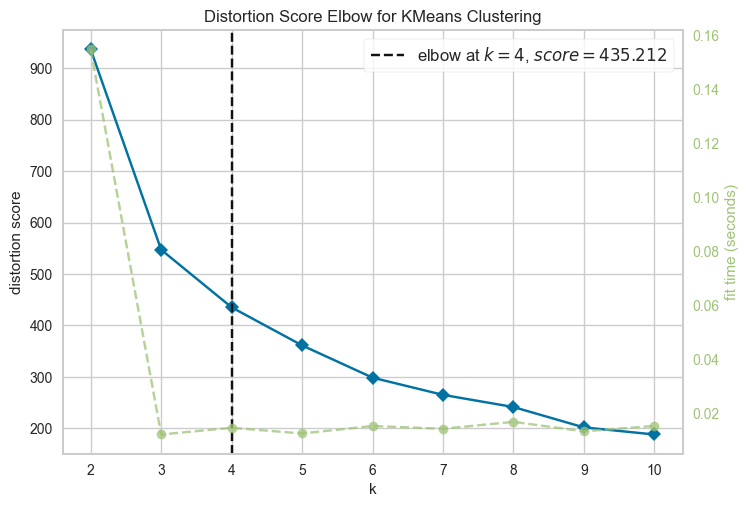

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [13]:
# importer KELbowVisualizer
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init= 'random', max_iter=500)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

#### <font color = "bisque"> Appliquer Kmeans en utilisant le k optimal

In [14]:
# Initier le modèle
kmeans_model = KMeans(n_clusters=4, init = 'random', max_iter=500)
# Entrainer le modèle
kmeans_model.fit(x)

,n_clusters,4
,init,'random'
,n_init,'auto'
,max_iter,500
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


#### <font color = "bisque"> Prédiction la partition

In [15]:
# Prediction de la partition(l'ensemble des classes) de X
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition

array([3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 3, 3, 3, 3, 3, 0, 3, 3, 0, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 2, 3, 3, 3, 2, 2, 3, 0, 3, 3, 3, 2, 3, 3,
       3, 3, 3, 3, 3, 2, 3, 3, 3, 3, 3, 3, 3, 3, 0, 0, 0, 3, 3, 3, 3, 0,
       2, 2, 2, 1, 2, 2, 2, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 2, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 2, 2, 2, 2, 2,
       2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       3, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0,
       0], dtype=int32)

In [16]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
val

0    67
3    56
1    47
2    29
Name: count, dtype: int64

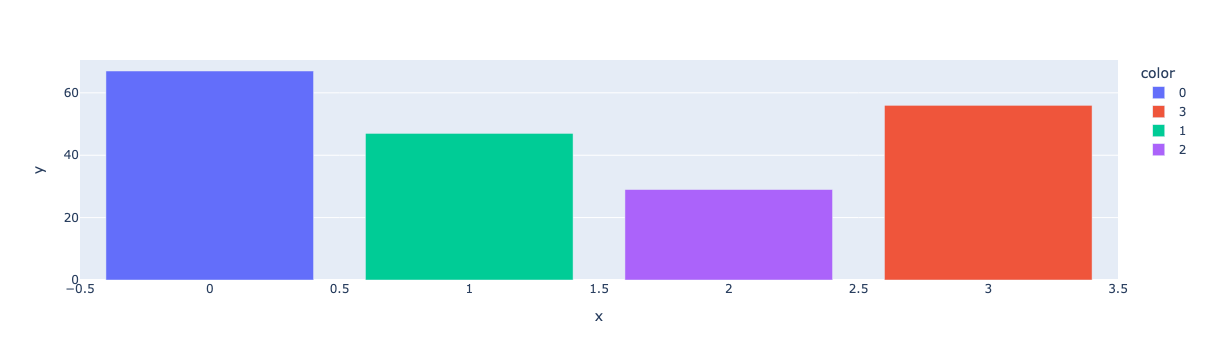

In [17]:
# Diagramme en barre du nombre d'observations dans chaque
import plotly.express as px
fig = px.bar(x=val.index , y = val.values,color=val.index.astype(str))
fig.show()

#### <font color = "bisque"> Visualiser les classes prédictes par Kmeans

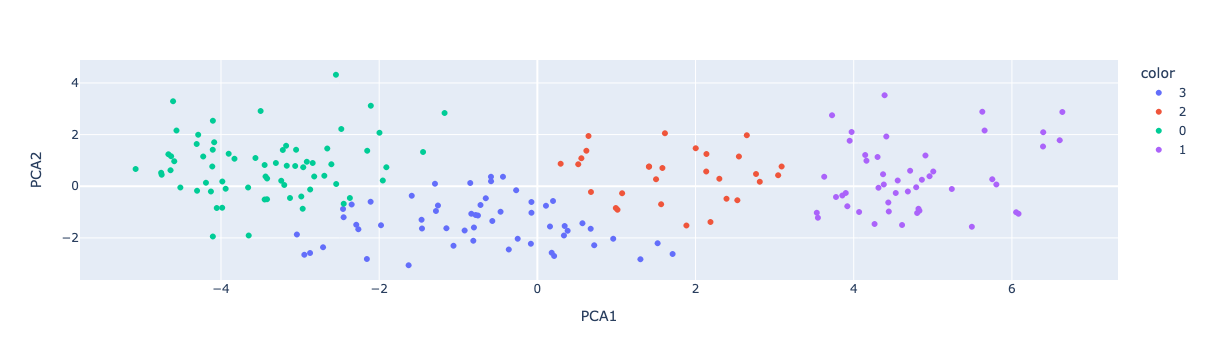

In [18]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(df_pca, x = 'PCA1', y = 'PCA2', color = kmeans_partition.astype(str))
fig.show()

<font color = "bisque">Indice de silhouette value de la partition du Kmeans

In [19]:
# Importer silhouette score
from sklearn.metrics import silhouette_score
# Indice de Silhouette value
sil_kmeans = silhouette_score(x,kmeans_partition)
print(f"silhouette score : {sil_kmeans}")

silhouette score : 0.4161494837480625


In [20]:
# Les graines de chaque classes
clusters_names = []
for i in range(4) :
    clusters_names.append(list(df.index[kmeans_partition == i] ))

In [21]:
# Afficher les graines de la classe 0
print(clusters_names[3])

['Graine 1', 'Graine 2', 'Graine 3', 'Graine 4', 'Graine 5', 'Graine 6', 'Graine 7', 'Graine 11', 'Graine 12', 'Graine 13', 'Graine 14', 'Graine 15', 'Graine 17', 'Graine 18', 'Graine 20', 'Graine 21', 'Graine 22', 'Graine 23', 'Graine 24', 'Graine 25', 'Graine 26', 'Graine 27', 'Graine 28', 'Graine 29', 'Graine 30', 'Graine 32', 'Graine 33', 'Graine 34', 'Graine 37', 'Graine 39', 'Graine 40', 'Graine 41', 'Graine 43', 'Graine 44', 'Graine 45', 'Graine 46', 'Graine 47', 'Graine 48', 'Graine 49', 'Graine 51', 'Graine 52', 'Graine 53', 'Graine 54', 'Graine 55', 'Graine 56', 'Graine 57', 'Graine 58', 'Graine 62', 'Graine 63', 'Graine 64', 'Graine 65', 'Graine 143', 'Graine 155', 'Graine 160', 'Graine 171', 'Graine 191']


### <font color='gold'> CAH

In [22]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

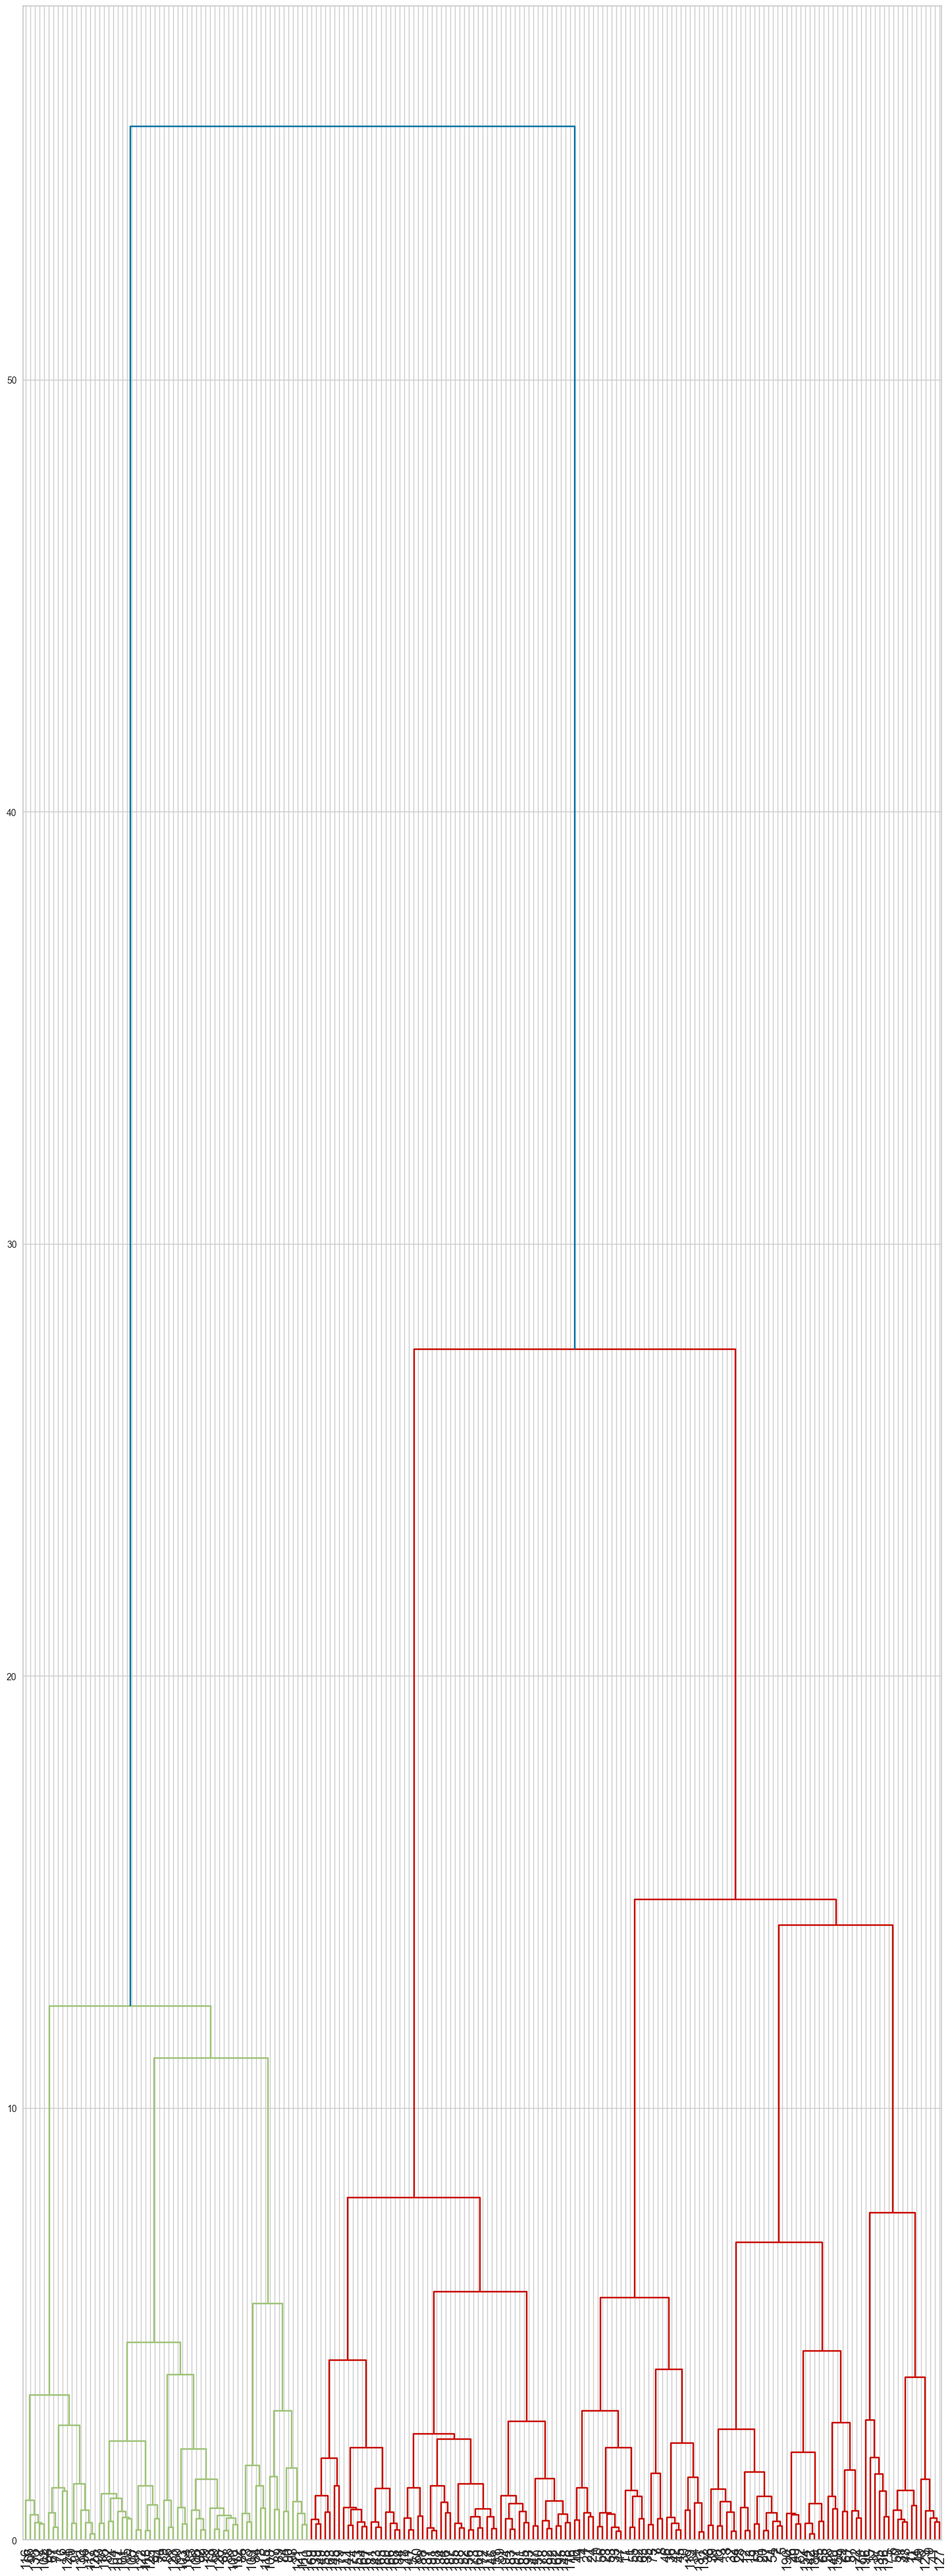

In [23]:
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(x, 'ward')# matrice des liaisons
plt.figure(figsize=(18, 50))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [24]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters =3, linkage = 'ward')
# Entrainer le modèle
cah_model.fit(x)

,n_clusters,3
,metric,'euclidean'
,memory,None
,connectivity,None
,compute_full_tree,'auto'
,linkage,'ward'
,distance_threshold,None
,compute_distances,False


In [25]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition[:100]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [26]:
# Nombre d'observations dans chaque classe
val1 = pd.Series(cah_partition).value_counts()
val1

0    80
1    62
2    57
Name: count, dtype: int64

In [27]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

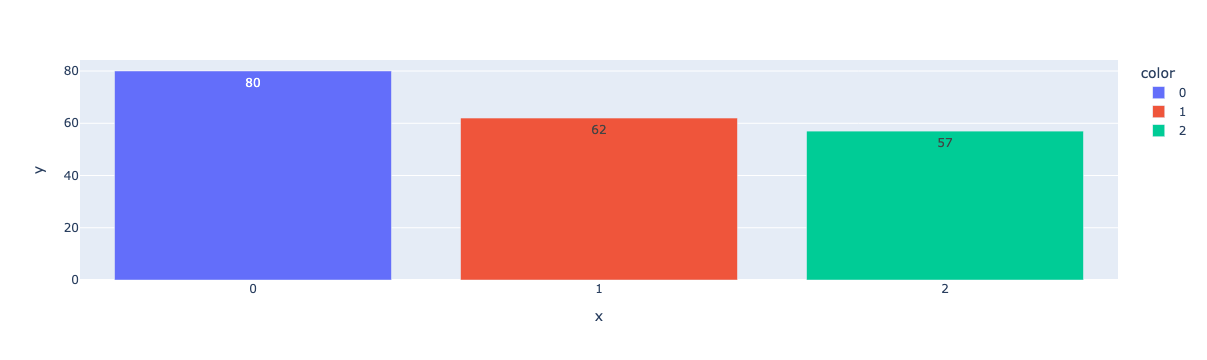

In [28]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

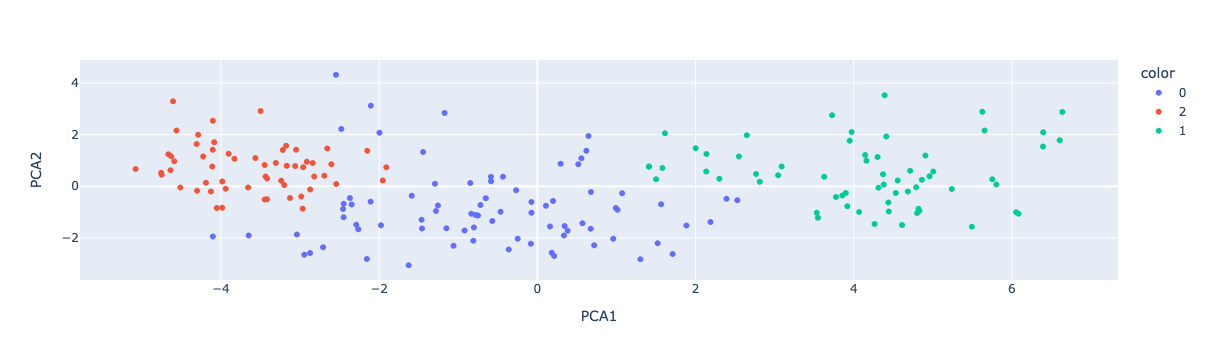

In [29]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(df_pca, x = 'PCA1', y = 'PCA2',color=cah_partition.astype(str))
fig.show()

In [30]:
# Silhouette score
from sklearn.metrics import silhouette_score
sil_cah = silhouette_score(x,cah_partition)
print(f"La silhouette score : {sil_cah} ")

La silhouette score : 0.428892653221629 


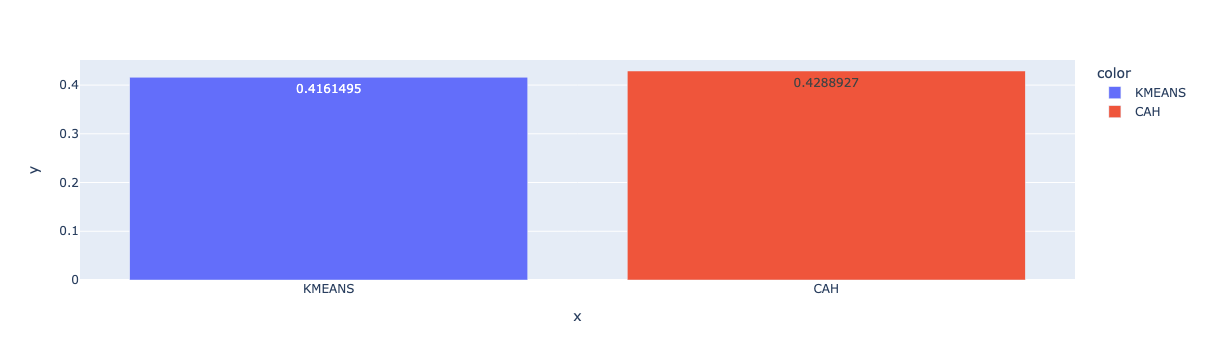

In [31]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [32]:
# les graines
cluster_names = []
for i in range(3):
  cluster_names.append(list(df.index[cah_partition == i]))

In [42]:
# Les individus de la classe 0
print(cluster_names[1][:10])

['Graine 67', 'Graine 68', 'Graine 69', 'Graine 70', 'Graine 71', 'Graine 72', 'Graine 73', 'Graine 74', 'Graine 75', 'Graine 77']


#### <font color='gold'> Interprétation les classes

In [34]:
# Profil moyen de chaque classe (sans les anomalies)
graines = df.groupby(cah_partition).mean().round(2)
graines

,area A,perimeter,compactness,length of kernel,width of kernel,asymmetry coefficient,length of kernel groove
0,14.29,14.30,0.88,5.52,3.23,2.91,5.16
1,18.61,16.26,0.88,6.20,3.71,3.67,6.06
2,11.78,13.21,0.85,5.22,2.84,4.83,5.09


In [38]:
import numpy as np
from scipy.spatial.distance import cdist

# Calculer les centroïdes
classes = np.unique(cah_partition)
centroides = np.array([x[cah_partition == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouveau_client):
    client = np.array(nouveau_client, dtype=float).reshape(1, -1)
    distances = cdist(client, centroides)
    return classes[distances.argmin()]

In [54]:
# telechargemebt du centroide 
jb.dump(centroides, "centroides_cah_wheat.joblib")

['centroides_cah_wheat.joblib']

In [52]:
# Test rapide
print("Classe prédite  :", predire_classe(df.iloc[2].values))
print("Classe réelle du cah:", cah_partition[2])

Classe prédite  : 0
Classe réelle du cah: 0


In [35]:
import joblib as jb
# telechargement du meilleur model 
jb.dump(cah_model,'model_graine.joblib')

['model_graine.joblib']

In [ ]:
# Noms des classes
noms_classes = {
    0: "Kama",
    1: "Rosa",
    2: "Canadian"
}